# Разбор бейзлайна

## Сравнение моделей

Проверю, выигрывает ли медиана района у общей медианы и даёт ли линейная регрессия улучшение на каждом фолде.

Беру прогнозы из outputs/baseline.csv. Для каждого дома это прогноз модели, которая обучалась на остальных фолдах.
Метрика - RMSE по логарифму цены: одинаковая относительная ошибка имеет одинаковый вес у дешёвого и дорогого дома.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import root_mean_squared_error

pred = pd.read_csv('../outputs/baseline.csv', index_col='Id')
cols = ['Id', 'SalePrice', 'GrLivArea', 'OverallQual']
houses = pd.read_csv('../data/raw/train.csv', usecols=cols, index_col='Id')
df = pred.join(houses)

In [2]:
models = ['median', 'hood', 'linear']
errors = np.log(df[models]).sub(np.log(df['SalePrice']), axis=0)
scores = errors.pow(2).groupby(df['fold']).mean().pow(0.5)
print('Сравнение RMSE разных моделей на кросс-валидации')
display(scores.round(4))
print('Среднее RMSE и стандартное отклонение по фолдам')
scores.agg(['mean', 'std']).round(4)

Сравнение RMSE разных моделей на кросс-валидации


,median,hood,linear
fold,,,
1,0.3990,0.2556,0.1493
2,0.3688,0.2278,0.1681
3,0.4064,0.2772,0.1999
4,0.4026,0.3010,0.1591
5,0.3853,0.2662,0.1543


Среднее RMSE и стандартное отклонение по фолдам


,median,hood,linear
mean,0.3924,0.2656,0.1661
std,0.0154,0.0270,0.0201


На каждом из пяти фолдов медиана района лучше общей медианы, а линейная регрессия лучше обеих. 

Дальше разберу линейную регрессию. Интересно, почему её RMSE отличается по фолдам: на худшем фолде модель чаще ошибается на обычных домах или несколько прогнозов-выбросов дают большую ошибку?

In [3]:
err = errors['linear']
typical = err.abs().groupby(df['fold']).median()
pd.DataFrame({
    'rmse': scores['linear'],
    'median_abs_log_error': typical,
}).round(4)

,rmse,median_abs_log_error
fold,,
1,0.1493,0.0800
2,0.1681,0.0941
3,0.1999,0.0775
4,0.1591,0.0947
5,0.1543,0.0955


Максимальный RMSE у фолда 3 = 0.1999. При этом медианная абсолютная ошибка у него самая низкая = 0.0775. 
Посмотрю, какие продажи дали наибольший вклад в RMSE этого фолда.

In [4]:
num_worst_fold = scores['linear'].idxmax()
worst_fold = df[df['fold'] == num_worst_fold].copy()

squared_error = err[worst_fold.index].pow(2)
worst_fold['share_pct'] = (100 * squared_error / squared_error.sum())
worst_fold.sort_values(by='share_pct', ascending=False).round(0).head(4)

,linear,median,hood,log_area,no_garage_area,ordinal,knn_3,knn_5,knn_10,knn_20,knn_30,linear_with_knn_features,fold,OverallQual,GrLivArea,SalePrice,share_pct
Id,,,,,,,,,,,,,,,,,
1299,1151344.0,164500.0,126750.0,729541.0,997429.0,1126217.0,441442.0,467982.0,464783.0,419498.0,381463.0,481255.0,3,10,5642,160000,39.0
496,80223.0,164500.0,108950.0,74076.0,81417.0,79331.0,89036.0,86605.0,90432.0,94834.0,88981.0,75105.0,3,4,720,34900,7.0
411,122051.0,164500.0,126750.0,124497.0,120163.0,121353.0,136625.0,132684.0,135960.0,127733.0,127909.0,125058.0,3,5,1276,60000,5.0
689,237557.0,164500.0,264500.0,239681.0,234392.0,241050.0,232450.0,248498.0,249859.0,244145.0,244744.0,252954.0,3,8,1419,392000,3.0


Дом 1299 дал 39.3% суммы квадратов ошибок фолда. Модель оценила его в 1151344 при цене продажи 160000. Следующие
по вкладу дома — 496 и 411. У них жилая площадь 720 и 1276 кв. футов. Большая площадь объясняет, почему дом 1299 интересно проверить отдельно, но не описывает все три ошибки.

## Что произошло с большими домами из EDA?

В EDA я выделил два самых больших дома по GrLivArea и ожидал завышенного прогноза для обоих. Найду их по тому же правилу среди всех валидационных прогнозов.

In [5]:
df.nlargest(2, 'GrLivArea').round()

,linear,median,hood,log_area,no_garage_area,ordinal,knn_3,knn_5,knn_10,knn_20,knn_30,linear_with_knn_features,fold,OverallQual,GrLivArea,SalePrice
Id,,,,,,,,,,,,,,,,
1299,1151344.0,164500.0,126750.0,729541.0,997429.0,1126217.0,441442.0,467982.0,464783.0,419498.0,381463.0,481255.0,3,10,5642,160000
524,623881.0,163990.0,119000.0,480384.0,627821.0,612278.0,420777.0,436545.0,462980.0,427102.0,396450.0,433609.0,2,10,4676,184750


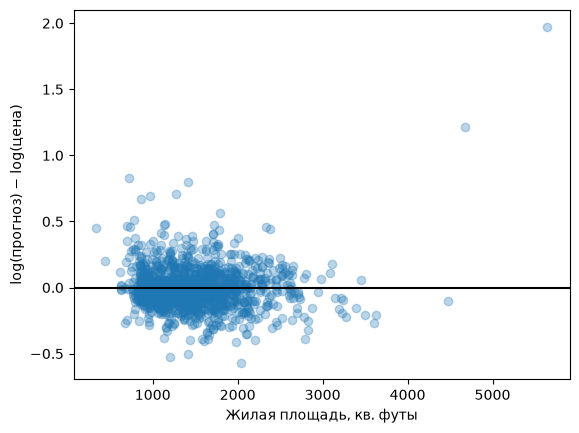

In [6]:
plt.scatter(df['GrLivArea'], err, alpha=0.3)
plt.axhline(0, color='black')
plt.xlabel('Жилая площадь, кв. футы')
plt.ylabel('log(прогноз) − log(цена)')
plt.show()

Две самые удалённые справа точки находятся выше нуля: модель завысила цену обоих самых больших домов. Крупные ошибки видны и при меньшей площади

In [7]:
houses = pd.read_csv('../data/raw/train.csv', index_col='Id')
cols = ['Neighborhood', 'GrLivArea', 'OverallQual', 'YearBuilt', 'YrSold', 'YearRemodAdd', 'SaleCondition', 'SalePrice']
houses.loc[[524, 1299], cols].join(pred).round(0).T

Id,524,1299
Neighborhood,Edwards,Edwards
GrLivArea,4676,5642
OverallQual,10,10
YearBuilt,2007,2008
YrSold,2007,2008
YearRemodAdd,2008,2008
SaleCondition,Partial,Partial
SalePrice,184750,160000
linear,623881.0,1151344.0
median,163990.0,164500.0


Оба дома попали в валидацию, но в разные фолды. Для дома 524 линейная модель предсказала 624 тыс. долларов при цене 185 тыс.,
для дома 1299 = 1,15 млн при цене 160 тыс. Медиана района в обоих случаях занизила цену, но оказалась ближе к факту.

Оба дома большие, с OverallQual = 10, оба проданы в Edwards в год постройки. У обоих SaleCondition = Partial: на момент 
последней оценки строительство ещё не закончилось. У дома 524 год реконструкции вообще позже продажи: 2008 против 2007.

Возможно, площадь и качество в этих строках описывают дом на более поздней стадии готовности, чем в момент сделки.
Для дома 524 на это указывают даты. Для дома 1299 точную стадию готовности в день продажи по данным определить нельзя.

## Как выглядит обычная ошибка?
Посмотрю, на сколько процентов линейная регрессия обычно ошибается в цене. Возьму два дома, для которых размер ошибки ближе всего к медианному.

In [8]:
pct = 100 * (df['linear'] / df['SalePrice'] - 1)
pct.abs().quantile([0.5, 0.9]).round(1)
distance = (pct.abs() - pct.abs().median()).abs()
ids = distance.nsmallest(2).index
df.assign(error_pct=pct).loc[ids, ['SalePrice', 'linear', 'error_pct']].round(1)

,SalePrice,linear,error_pct
Id,,,
1296,138500,126361.9,-8.8
546,229000,249019.5,8.7


In [9]:
pct.abs().quantile([0.5, 0.9]).round(1)

0.5     8.8
0.9    24.4
dtype: float64

У половины домов прогноз отличается от цены продажи не больше чем на 8.8%, у 90% домов — не больше чем на 24.4%.

Например, дом 1296 продали за 138500, а модель дала 126362 (−8.8%). Дом 546 продали за 229000, прогноз — 249019 (+8.7%).
Для обычной по размеру ошибки встречаются оба направления: модель может как недооценить дом, так и переоценить его.

## Абляции линейной регрессии

In [10]:
ablations = ['linear', 'log_area', 'no_garage_area', 'ordinal']
err = np.log(df[ablations]).sub(np.log(df['SalePrice']), axis=0)
rmse = err.pow(2).groupby(df['fold']).mean().pow(0.5)
display(rmse.round(4))
rmse.agg(['mean', 'std']).round(4)

,linear,log_area,no_garage_area,ordinal
fold,,,,
1,0.1493,0.1489,0.1501,0.1492
2,0.1681,0.1581,0.1683,0.1670
3,0.1999,0.1843,0.1964,0.1985
4,0.1591,0.1525,0.1599,0.1592
5,0.1543,0.1532,0.1542,0.1535


,linear,log_area,no_garage_area,ordinal
mean,0.1661,0.1594,0.1658,0.1655
std,0.0201,0.0143,0.0184,0.0196


Проверим два больших, но дешевых дома на новых моделях, ожидаем, что взятие логарифма от площади должно было помочь

In [11]:
df.nlargest(2, 'GrLivArea').round()

,linear,median,hood,log_area,no_garage_area,ordinal,knn_3,knn_5,knn_10,knn_20,knn_30,linear_with_knn_features,fold,OverallQual,GrLivArea,SalePrice
Id,,,,,,,,,,,,,,,,
1299,1151344.0,164500.0,126750.0,729541.0,997429.0,1126217.0,441442.0,467982.0,464783.0,419498.0,381463.0,481255.0,3,10,5642,160000
524,623881.0,163990.0,119000.0,480384.0,627821.0,612278.0,420777.0,436545.0,462980.0,427102.0,396450.0,433609.0,2,10,4676,184750


Вывод

Передача логарифма жилой площади помогла улучшить качество предсказаний на трейне за счет уменьшения ошибки на выбросах.
После логарифмирования GrLivArea средний RMSE улучшился на каждом из пяти фолдов. 
У двух самых больших домов прогнозы стали ближе к цене продажи, хотя модель всё ещё переоценила оба дома.

## KNN - как показывает себя и сколько соседей брать

Проверю, помогает ли усреднение по большему числу похожих домов.
Меняю только k: 3, 5, 10 и 20. Фолды и признаки одни и те же.
Для сравнения беру медиану района, линейную регрессию на тех же
четырёх признаках и лучшую линейную модель из предыдущего раздела.

In [12]:
models = ['hood', 'knn_3', 'knn_5', 'knn_10', 'knn_20', 'knn_30', 'linear_with_knn_features', 'log_area']
err = np.log(df[models]).sub(np.log(df['SalePrice']), axis=0)
rmse = err.pow(2).groupby(df['fold']).mean().pow(0.5)
display(rmse.round(4))
rmse.agg(['mean', 'std']).T.round(4)

,hood,knn_3,knn_5,knn_10,knn_20,knn_30,linear_with_knn_features,log_area
fold,,,,,,,,
1,0.2556,0.1658,0.1684,0.1711,0.1801,0.1850,0.1597,0.1489
2,0.2278,0.1761,0.1739,0.1718,0.1641,0.1630,0.1556,0.1581
3,0.2772,0.2125,0.2052,0.1969,0.1969,0.1948,0.1841,0.1843
4,0.3010,0.1801,0.1776,0.1840,0.1880,0.1937,0.1652,0.1525
5,0.2662,0.2002,0.1925,0.1890,0.1808,0.1852,0.1668,0.1532


,mean,std
hood,0.2656,0.0270
knn_3,0.1869,0.0190
knn_5,0.1835,0.0151
knn_10,0.1826,0.0111
knn_20,0.1820,0.0121
knn_30,0.1843,0.0128
linear_with_knn_features,0.1663,0.0109
log_area,0.1594,0.0143


Ошибка KNN снижается с ростом k до какого-то момента, но по отдельным фолдам картина разная. 
Например, на первом фолде лучший knn получился при k=3, а на втором при k=30. Между k=10 и k=20 разницы не оч много.

Даже при лучшем из проверенных k линейная регрессия на тех же признаках точнее на всех пяти фолдах.